# Eksperimen SML - AI4I 2020 Predictive Maintenance

## 1. Perkenalan Dataset
**AI4I 2020 Predictive Maintenance Dataset** adalah data sintetis tabular (10.000 baris) yang meniru kondisi mesin manufaktur.

| Kolom | Keterangan |
|---|---|
| `UDI`, `Product ID` | Identitas baris / produk (tidak informatif untuk model) |
| `Type` | Kualitas produk: L (low), M (medium), H (high) |
| `Air temperature [K]`, `Process temperature [K]` | Suhu udara dan suhu proses |
| `Rotational speed [rpm]`, `Torque [Nm]`, `Tool wear [min]` | Sensor mekanis |
| `Machine failure` | **Target**: 0 = normal, 1 = gagal |
| `TWF`, `HDF`, `PWF`, `OSF`, `RNF` | Mode kegagalan spesifik: **data leakage** karena menentukan target secara langsung |

Tujuan: memprediksi `Machine failure` dari pembacaan sensor, sehingga perawatan bisa dijadwalkan sebelum mesin rusak.

## 2. Import Library

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.preprocessing import OrdinalEncoder, StandardScaler

pd.set_option("display.max_columns", None)

## 3. Memuat Dataset

In [2]:
RAW_PATH = Path("../ai4i2020_raw/ai4i2020.csv")
df = pd.read_csv(RAW_PATH)
print("Shape:", df.shape)
df.head()

Shape: (10000, 14)


,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


## 4. Exploratory Data Analysis (EDA)

### 4.1 Struktur data dan missing value

In [3]:
df.info()
print("\nMissing value per kolom:")
print(df.isna().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   UDI                      10000 non-null  int64  
 1   Product ID               10000 non-null  object 
 2   Type                     10000 non-null  object 
 3   Air temperature [K]      10000 non-null  float64
 4   Process temperature [K]  10000 non-null  float64
 5   Rotational speed [rpm]   10000 non-null  int64  
 6   Torque [Nm]              10000 non-null  float64
 7   Tool wear [min]          10000 non-null  int64  
 8   Machine failure          10000 non-null  int64  
 9   TWF                      10000 non-null  int64  
 10  HDF                      10000 non-null  int64  
 11  PWF                      10000 non-null  int64  
 12  OSF                      10000 non-null  int64  
 13  RNF                      10000 non-null  int64  
dtypes: float64(3), int64(9)

### 4.2 Duplikasi

In [4]:
print("Baris duplikat (seluruh kolom):", df.duplicated().sum())
print("Duplikat UDI:", df["UDI"].duplicated().sum())
print("Duplikat Product ID:", df["Product ID"].duplicated().sum())

Baris duplikat (seluruh kolom): 0
Duplikat UDI: 0
Duplikat Product ID: 0


### 4.3 Statistik deskriptif

In [5]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
UDI,10000.0,5000.50000,2886.895680,1.0,2500.75,5000.5,7500.25,10000.0
Air temperature [K],10000.0,300.00493,2.000259,295.3,298.30,300.1,301.50,304.5
Process temperature [K],10000.0,310.00556,1.483734,305.7,308.80,310.1,311.10,313.8
Rotational speed [rpm],10000.0,1538.77610,179.284096,1168.0,1423.00,1503.0,1612.00,2886.0
Torque [Nm],10000.0,39.98691,9.968934,3.8,33.20,40.1,46.80,76.6
Tool wear [min],10000.0,107.95100,63.654147,0.0,53.00,108.0,162.00,253.0
Machine failure,10000.0,0.03390,0.180981,0.0,0.00,0.0,0.00,1.0
TWF,10000.0,0.00460,0.067671,0.0,0.00,0.0,0.00,1.0
HDF,10000.0,0.01150,0.106625,0.0,0.00,0.0,0.00,1.0
PWF,10000.0,0.00950,0.097009,0.0,0.00,0.0,0.00,1.0


### 4.4 Distribusi target (fluktuasi kelas)

Machine failure
0    9661
1     339
Name: count, dtype: int64
Machine failure
0    96.61 %
1     3.39 %
Name: count, dtype: object


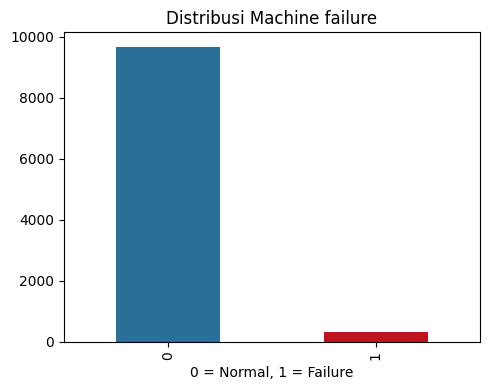

In [6]:
counts = df["Machine failure"].value_counts()
print(counts)
print((counts / len(df) * 100).round(2).astype(str) + " %")

fig, ax = plt.subplots(figsize=(5, 4))
counts.plot(kind="bar", color=["#2a6f97", "#c1121f"], ax=ax)
ax.set_title("Distribusi Machine failure")
ax.set_xlabel("0 = Normal, 1 = Failure")
plt.tight_layout()
plt.show()

Kelas failure sangat sedikit (data **imbalanced**), sehingga model nanti memakai `class_weight='balanced'`.

### 4.5 Korelasi

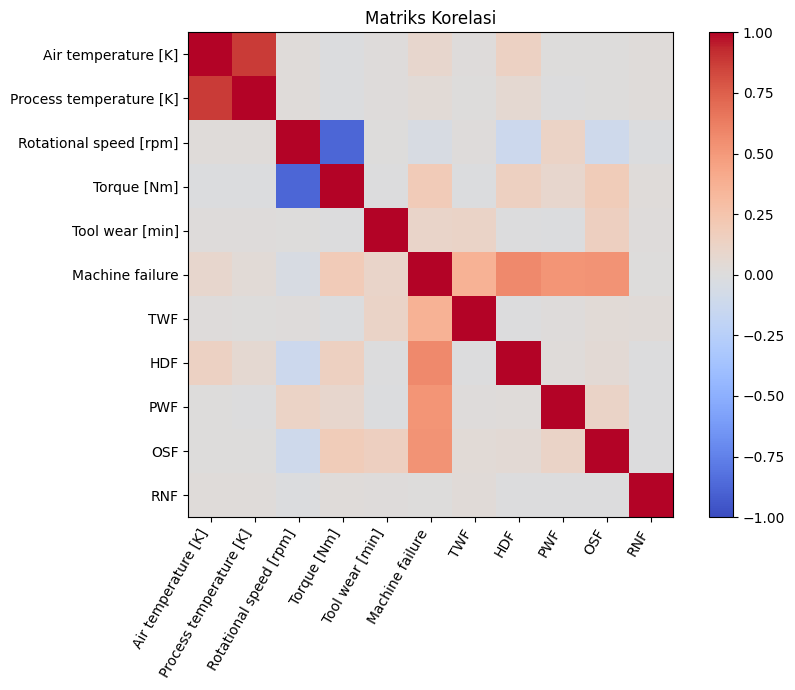

Machine failure            1.000000
HDF                        0.575800
OSF                        0.531083
PWF                        0.522812
TWF                        0.362904
Torque [Nm]                0.191321
Tool wear [min]            0.105448
Air temperature [K]        0.082556
Process temperature [K]    0.035946
RNF                        0.004516
Rotational speed [rpm]    -0.044188
Name: Machine failure, dtype: float64

In [7]:
numeric_cols = df.select_dtypes(include=np.number).columns.drop(["UDI"])
corr = df[numeric_cols].corr()

fig, ax = plt.subplots(figsize=(9, 7))
im = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr.columns)))
ax.set_xticklabels(corr.columns, rotation=60, ha="right")
ax.set_yticks(range(len(corr.columns)))
ax.set_yticklabels(corr.columns)
fig.colorbar(im, ax=ax)
ax.set_title("Matriks Korelasi")
plt.tight_layout()
plt.show()

corr["Machine failure"].sort_values(ascending=False)

Kolom `TWF`, `HDF`, `PWF`, `OSF` berkorelasi sangat kuat dengan `Machine failure` karena merupakan penyebab langsung target (**leakage**), sehingga harus dibuang saat pelatihan.

## 5. Data Preprocessing

### 5.1 Drop `UDI` dan `Product ID`

In [8]:
df_clean = df.drop(columns=["UDI", "Product ID"])
df_clean.columns.tolist()

['Type',
 'Air temperature [K]',
 'Process temperature [K]',
 'Rotational speed [rpm]',
 'Torque [Nm]',
 'Tool wear [min]',
 'Machine failure',
 'TWF',
 'HDF',
 'PWF',
 'OSF',
 'RNF']

### 5.2 Drop kolom leakage `TWF`, `HDF`, `PWF`, `OSF`, `RNF`

In [9]:
LEAKAGE_COLS = ["TWF", "HDF", "PWF", "OSF", "RNF"]
df_clean = df_clean.drop(columns=LEAKAGE_COLS).dropna().reset_index(drop=True)
df_clean.head()

,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure
0,M,298.1,308.6,1551,42.8,0,0
1,L,298.2,308.7,1408,46.3,3,0
2,L,298.1,308.5,1498,49.4,5,0
3,L,298.2,308.6,1433,39.5,7,0
4,L,298.2,308.7,1408,40.0,9,0


### 5.3 Ordinal Encoder untuk `Type` (L=0, M=1, H=2)

In [10]:
encoder = OrdinalEncoder(categories=[["L", "M", "H"]])
df_enc = df_clean.copy()
df_enc["Type"] = encoder.fit_transform(df_enc[["Type"]]).astype(int).ravel()
df_enc["Type"].value_counts().sort_index()

Type
0    6000
1    2997
2    1003
Name: count, dtype: int64

### 5.4 StandardScaler untuk seluruh sensor numerik

In [11]:
NUMERIC_FEATURES = [
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]",
]
scaler = StandardScaler()
df_scaled = df_enc.copy()
df_scaled[NUMERIC_FEATURES] = scaler.fit_transform(df_scaled[NUMERIC_FEATURES])
df_final = df_scaled[["Type", *NUMERIC_FEATURES, "Machine failure"]]
df_final[NUMERIC_FEATURES].describe().T[["mean", "std"]]

,mean,std
Air temperature [K],-9.322321e-16,1.00005
Process temperature [K],-1.693934e-15,1.00005
Rotational speed [rpm],-2.330580e-16,1.00005
Torque [Nm],5.424994e-16,1.00005
Tool wear [min],1.051603e-16,1.00005


### 5.5 Simpan hasil
Versi otomatis dari seluruh langkah di atas ada di `automate_siswa.py`.

In [12]:
OUTPUT_DIR = Path("ai4i2020_preprocessing_eksperimen")
OUTPUT_DIR.mkdir(exist_ok=True)
df_final.to_csv(OUTPUT_DIR / "ai4i2020_preprocessing.csv", index=False)
print("Tersimpan:", df_final.shape)
df_final.head()

Tersimpan: (10000, 7)


,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure
0,1,-0.952389,-0.947360,0.068185,0.282200,-1.695984,0
1,0,-0.902393,-0.879959,-0.729472,0.633308,-1.648852,0
2,0,-0.952389,-1.014761,-0.227450,0.944290,-1.617430,0
3,0,-0.902393,-0.947360,-0.590021,-0.048845,-1.586009,0
4,0,-0.902393,-0.879959,-0.729472,0.001313,-1.554588,0
